# Paired RNA-pool redistribution

Estimate ASD-associated polysome–monosome redistribution with Monopoly.


In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from monopoly import MonopolyDataset, MonopolyModel
from monopoly import __version__ as monopoly_version
from scipy.stats import spearmanr

REFERENCE = 'Unaffected'
TEST = 'ASD'
ALPHA = 0.05
MIN_COUNT = 10
N_CPUS = min(4, os.cpu_count() or 1)
EXPECTED_MONOPOLY_VERSION = '0.1.0'
FRACTIONS = {
    'input': ('Input', 'input'),
    'monosome': ('Monosome', 'mono'),
    'polysome': ('Polysome', 'poly'),
}
CONTRASTS = {
    'polysomeMonosome': ('poly', 'mono'),
    'polysomeInput': ('poly', 'input'),
    'monosomeInput': ('mono', 'input'),
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load participant metadata.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok = True)

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
metadata['condition'] = pd.Categorical(
    metadata['condition'],
    categories = [REFERENCE, TEST],
)
sample_ids = metadata.index.tolist()
min_samples = int(metadata['condition'].value_counts().min())

if monopoly_version != EXPECTED_MONOPOLY_VERSION:
    raise RuntimeError(
        f'Expected Monopoly {EXPECTED_MONOPOLY_VERSION}, found {monopoly_version}.'
    )
if metadata['condition'].isna().any():
    raise ValueError('Metadata contains an unexpected condition.')
if min_samples < 2:
    raise ValueError('Each condition requires at least two participants.')

display(metadata)


,familyId,condition
sampleId,,
07c06,1077,Unaffected
07c13,1077,Unaffected
07c16,1077,Unaffected
1851,1077,ASD
1861,1077,ASD
1916,1077,ASD


In [3]:
# Align and round length-scaled Salmon gene counts once.


def prepare_counts(folder: str, prefix: str):
    path = DATA_DIR / folder / 'salmon.merged.gene_counts_length_scaled.tsv'
    table = pd.read_csv(path, sep = '\t')
    columns = [f'{prefix}{sample_id}' for sample_id in sample_ids]
    missing = {'gene_id', 'gene_name', *columns}.difference(table.columns)

    if missing:
        raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
    if table['gene_id'].isna().any() or not table['gene_id'].is_unique:
        raise ValueError(f'Gene identifiers must be complete and unique in {folder}.')

    names = table.set_index('gene_id')['gene_name'].rename('geneName')
    counts = table.set_index('gene_id').loc[:, columns]
    values = counts.to_numpy(dtype = 'float64')

    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError(f'Counts must be finite and nonnegative in {folder}.')

    counts.columns = sample_ids
    counts = np.rint(counts.T).astype('int64')
    counts.index.name = 'sampleId'
    counts.columns.name = 'geneId'
    return counts, names


counts = {}
gene_names = {}

for fraction, (folder, prefix) in FRACTIONS.items():
    counts[fraction], gene_names[fraction] = prepare_counts(folder, prefix)

for fraction in ('monosome', 'polysome'):
    if not gene_names['input'].index.equals(gene_names[fraction].index):
        raise ValueError(f'{fraction.title()} gene identifiers are not aligned.')
    if not gene_names['input'].equals(gene_names[fraction]):
        raise ValueError(f'{fraction.title()} gene annotations are not aligned.')

# The primary filter is condition-blind and requires support in both target pools.
mono_keep = counts['monosome'].ge(MIN_COUNT).sum(axis = 0).ge(min_samples)
poly_keep = counts['polysome'].ge(MIN_COUNT).sum(axis = 0).ge(min_samples)
keep = mono_keep & poly_keep

filter_summary = pd.DataFrame({
    'criterion': [
        'all genes',
        'monosome threshold',
        'polysome threshold',
        'both thresholds',
    ],
    'genes': [
        len(keep),
        int(mono_keep.sum()),
        int(poly_keep.sum()),
        int(keep.sum()),
    ],
    'minimumCount': [pd.NA, MIN_COUNT, MIN_COUNT, MIN_COUNT],
    'minimumSamples': [pd.NA, min_samples, min_samples, min_samples],
})

for fraction in FRACTIONS:
    counts[fraction] = counts[fraction].loc[:, keep]

names = gene_names['input'].loc[keep]
gene_metadata = names.to_frame()
display(filter_summary)


,criterion,genes,minimumCount,minimumSamples
0,all genes,78941,<NA>,<NA>
1,monosome threshold,21888,10,3
2,polysome threshold,21256,10,3
3,both thresholds,20470,10,3


In [4]:
# Fit one participant-paired condition-by-fraction model.

dataset = MonopolyDataset(
    input = counts['input'],
    monosome = counts['monosome'],
    polysome = counts['polysome'],
    metadata = metadata,
    gene_metadata = gene_metadata,
)
model = MonopolyModel(
    dataset = dataset,
    reference = REFERENCE,
).fit(
    normalization = 'fraction',
    fit_type = 'parametric',
    size_factor_fit_type = 'ratio',
    n_cpus = N_CPUS,
)

design = model.design_matrix
design_summary = pd.DataFrame({
    'libraries': [design.shape[0]],
    'parameters': [design.shape[1]],
    'rank': [np.linalg.matrix_rank(design.to_numpy())],
    'residualDegreesOfFreedom': [design.shape[0] - design.shape[1]],
})

if design_summary.loc[0, 'rank'] != design.shape[1]:
    raise ValueError('The design matrix is not full rank.')
if design_summary.loc[0, 'residualDegreesOfFreedom'] <= 0:
    raise ValueError('The design has no residual degrees of freedom.')
if model.fit_summary['failedGenes']:
    raise RuntimeError('At least one gene failed model fitting.')

display(design_summary)
display(pd.DataFrame([model.fit_summary]))


,libraries,parameters,rank,residualDegreesOfFreedom
0,18,10,10,8


,totalGenes,fittedGenes,allZeroGenes,failedGenes,cooksAvailable,cooksFilteringAvailable,outlierRefittingAvailable,normalization,dispersionModel,requestedFitType,effectiveFitType,requestedSizeFactorFitType,effectiveSizeFactorFitType
0,20470,20470,0,0,True,False,False,fraction,shared,parametric,parametric,ratio,"{'input': 'ratio', 'monosome': 'ratio', 'polys..."


In [5]:
# Derive the primary and secondary contrasts from the same fitted model.

contrast_results = {
    name: model.contrast(
        numerator,
        denominator,
        alpha = ALPHA,
        cooks_filter = False,
        independent_filter = True,
    )
    for name, (numerator, denominator) in CONTRASTS.items()
}
result_tables = {
    name: result.table.set_index('geneId')
    for name, result in contrast_results.items()
}

contrast_records = []

for name, result in contrast_results.items():
    table = result.table
    diagnostics = result.diagnostics

    if not table['geneId'].equals(diagnostics['geneId']):
        raise ValueError(f'{name} results and diagnostics are not aligned.')
    if not table['geneId'].is_unique:
        raise ValueError(f'{name} contains duplicate gene identifiers.')

    contrast_records.append({
        'contrast': name,
        'genes': len(table),
        'fittedGenes': int(diagnostics['fitStatus'].eq('fitted').sum()),
        'failedGenes': int(diagnostics['fitStatus'].eq('failed').sum()),
        'backendCooksFlags': int(diagnostics['cooksOutlier'].sum()),
        'independentlyFilteredGenes': int(diagnostics['independentFilter'].sum()),
        'workingModelFdrGenes': int(
            table['adjustedPValue'].lt(ALPHA).sum()
        ),
        'positiveEffect': result.provenance['contrast']['positiveEffect'],
    })

contrast_summary = pd.DataFrame(contrast_records)
display(contrast_summary)

for name, table in result_tables.items():
    diagnostics = contrast_results[name].diagnostics.set_index('geneId')
    leading = table.join(diagnostics[['maxCooks']])
    print(f'{name} leading results')
    display(
        leading.sort_values(
            ['adjustedPValue', 'pValue'],
            na_position = 'last',
        ).head(10)
    )


,contrast,genes,fittedGenes,failedGenes,backendCooksFlags,independentlyFilteredGenes,workingModelFdrGenes,positiveEffect
0,polysomeMonosome,20470,20470,0,0,0,22,polysome-to-monosome ratio is higher in ASD th...
1,polysomeInput,20470,20470,0,0,0,6,polysome-to-input ratio is higher in ASD than ...
2,monosomeInput,20470,20470,0,0,0,2,monosome-to-input ratio is higher in ASD than ...


polysomeMonosome leading results


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,maxCooks
geneId,,,,,,,,
ENSG00000181965.6,NEUROG1,3950.302323,1.421099,0.250185,5.680203,1.345349e-08,0.000228,0.022061
ENSG00000292338.2,DHRSX,1518.974715,5.035793,0.906649,5.554292,2.787391e-08,0.000228,0.210904
ENSG00000165462.6,PHOX2A,2192.459729,1.521502,0.275507,5.522552,3.341110e-08,0.000228,0.010575
ENSG00000115884.13,SDC1,4282.239358,0.979889,0.196988,4.974347,6.546787e-07,0.003246,0.006078
ENSG00000131747.17,TOP2A,4227.886892,-2.268728,0.459523,-4.937132,7.927987e-07,0.003246,0.132867
ENSG00000256802.4,LCIIAR,28.485732,6.310547,1.291508,4.886185,1.028085e-06,0.003484,0.261262
ENSG00000274641.2,H2BC17,110.959392,-5.244216,1.079713,-4.857044,1.191510e-06,0.003484,5.218421
ENSG00000138136.9,LBX1,9883.551699,1.169412,0.244439,4.784067,1.717834e-06,0.004383,0.017289
ENSG00000089154.13,GCN1,5446.271663,-1.311467,0.275464,-4.760942,1.926916e-06,0.004383,0.028412


polysomeInput leading results


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,maxCooks
geneId,,,,,,,,
ENSG00000292338.2,DHRSX,1518.974715,4.490472,0.906846,4.951747,7.355031e-07,0.008076,0.210904
ENSG00000292360.2,LINC03112,418.805579,11.333555,2.319277,4.886675,1.025531e-06,0.008076,0.790037
ENSG00000002587.12,HS3ST1,876.581068,2.016315,0.415019,4.858369,1.183569e-06,0.008076,0.059166
ENSG00000286496.2,ENSG00000286496,57.607263,4.530512,0.974370,4.649682,3.324476e-06,0.013788,0.254829
ENSG00000269242.1,ENSG00000269242,666.194091,-10.247034,2.205083,-4.647006,3.367879e-06,0.013788,0.188438
ENSG00000080608.12,PUM3,522.845673,-1.879644,0.432524,-4.345761,1.387933e-05,0.047352,0.250841
ENSG00000167895.18,TMC8,113.384933,-3.247023,0.830298,-3.910672,9.203981e-05,0.217617,0.613616
ENSG00000301688.1,ENSG00000301688,132.448517,2.332463,0.598801,3.895224,9.810812e-05,0.217617,0.110766
ENSG00000213648.13,SULT1A4,164.757120,-1.981723,0.509095,-3.892641,9.915893e-05,0.217617,0.051308


monosomeInput leading results


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,maxCooks
geneId,,,,,,,,
ENSG00000165462.6,PHOX2A,2192.459729,-1.621880,0.278079,-5.832446,5.462057e-09,0.000112,0.010575
ENSG00000181965.6,NEUROG1,3950.302323,-1.265495,0.250356,-5.054784,4.308781e-07,0.004410,0.022061
ENSG00000089154.13,GCN1,5446.271663,1.224142,0.274853,4.453807,8.436080e-06,0.052464,0.028412
ENSG00000253636.2,ENSG00000253636,76.904748,3.604459,0.817005,4.411793,1.025180e-05,0.052464,0.137242
ENSG00000204961.8,PCDHA9,92.917204,3.584176,0.849821,4.217566,2.469537e-05,0.093105,0.142426
ENSG00000269242.1,ENSG00000269242,666.194091,-9.248817,2.204738,-4.194974,2.729029e-05,0.093105,0.188438
ENSG00000143224.20,PPOX,1952.586983,-0.969177,0.236759,-4.093514,4.248849e-05,0.124248,0.046860
ENSG00000162520.17,SYNC,273.067932,3.272813,0.860519,3.803302,1.427802e-04,0.336267,1.632933
ENSG00000161270.21,NPHS1,60.821255,3.733817,0.989511,3.773395,1.610408e-04,0.336267,0.443253


,fraction,minimumSizeFactor,geometricMeanSizeFactor,maximumSizeFactor
0,input,0.962692,1.004049,1.102765
1,monosome,0.850901,1.005962,1.147851
2,polysome,0.889900,1.004837,1.219442


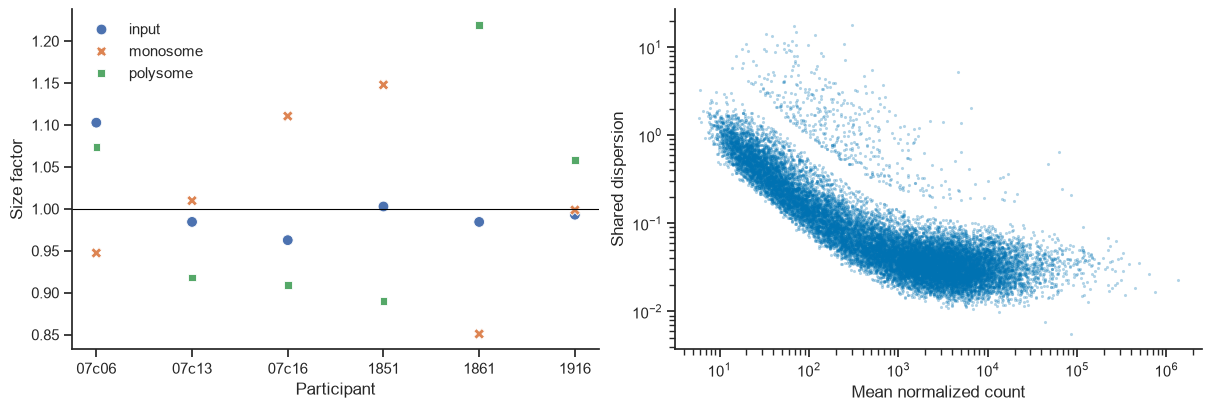

In [6]:
# Verify fraction-wise normalization and inspect the shared dispersion model.

size_factors = model.size_factors.reset_index()
size_factors['condition'] = size_factors['participantId'].map(
    metadata['condition']
)
normalization_summary = size_factors.groupby('fraction', observed = True)[
    'sizeFactor'
].agg(
    minimumSizeFactor = 'min',
    geometricMeanSizeFactor = lambda x: np.exp(np.log(x).mean()),
    maximumSizeFactor = 'max',
).reset_index()

if not np.isfinite(size_factors['sizeFactor']).all():
    raise ValueError('Size factors must be finite.')
if not size_factors['sizeFactor'].gt(0).all():
    raise ValueError('Size factors must be positive.')

normalized_means = model.normalized_counts.mean(axis = 0)
dispersions = model.dispersions
display(normalization_summary)

figure, axes = plt.subplots(1, 2, figsize = (12, 4), constrained_layout = True)

sns.scatterplot(
    data = size_factors,
    x = 'participantId',
    y = 'sizeFactor',
    hue = 'fraction',
    style = 'fraction',
    s = 60,
    ax = axes[0],
)
axes[0].axhline(1, color = 'black', linewidth = 0.8)
axes[0].set(xlabel = 'Participant', ylabel = 'Size factor')
axes[0].legend(title = '', frameon = False)

axes[1].scatter(
    normalized_means,
    dispersions,
    color = '#0072B2',
    s = 5,
    alpha = 0.3,
    linewidths = 0,
    rasterized = True,
)
axes[1].set(
    xscale = 'log',
    yscale = 'log',
    xlabel = 'Mean normalized count',
    ylabel = 'Shared dispersion',
)

sns.despine()
plt.show()


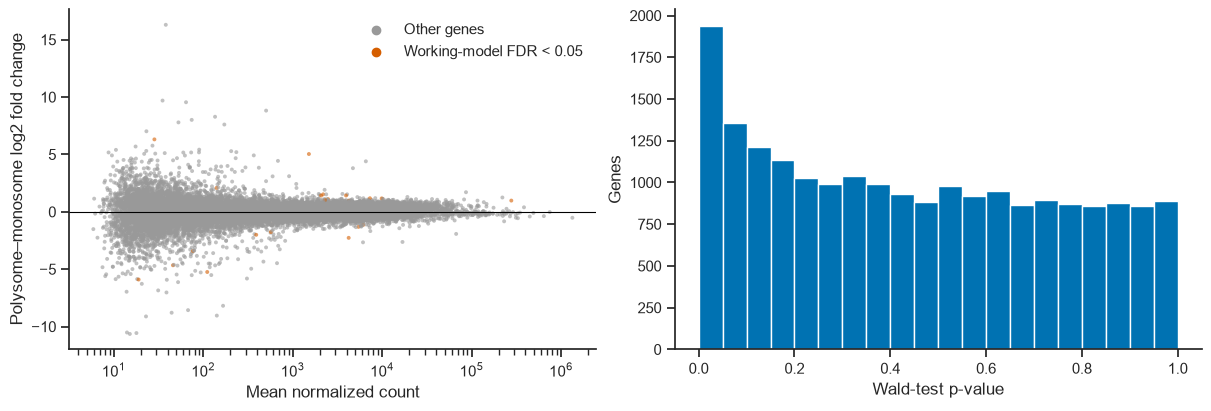

In [7]:
# Inspect the primary effect estimates and working-model p-values.

primary = result_tables['polysomeMonosome']
diagnostic = primary['adjustedPValue'].lt(ALPHA)
colors = np.where(diagnostic, '#D55E00', '#999999')

figure, axes = plt.subplots(1, 2, figsize = (12, 4), constrained_layout = True)
axes[0].scatter(
    primary['baseMean'],
    primary['log2FoldChange'],
    c = colors,
    s = 8,
    alpha = 0.6,
    linewidths = 0,
    rasterized = True,
)
axes[0].axhline(0, color = 'black', linewidth = 0.8)
axes[0].scatter(
    [],
    [],
    color = '#999999',
    label = 'Other genes',
)
axes[0].scatter(
    [],
    [],
    color = '#D55E00',
    label = 'Working-model FDR < 0.05',
)
axes[0].set(
    xscale = 'log',
    xlabel = 'Mean normalized count',
    ylabel = 'Polysome–monosome log2 fold change',
)
axes[0].legend(frameon = False)

axes[1].hist(
    primary['pValue'].dropna(),
    bins = np.linspace(0, 1, 21),
    color = '#0072B2',
    edgecolor = 'white',
)
axes[1].set(xlabel = 'Wald-test p-value', ylabel = 'Genes')

sns.despine()
plt.show()


In [8]:
# Review influential genes without automatically filtering unique paired cells.

primary_diagnostics = contrast_results['polysomeMonosome'].diagnostics
influence = primary_diagnostics.sort_values('maxCooks', ascending = False)
influence_summary = pd.DataFrame({
    'genes': [len(influence)],
    'finiteMaxCooks': [int(np.isfinite(influence['maxCooks']).sum())],
    'backendCooksFlags': [int(influence['cooksOutlier'].sum())],
    'medianMaxCooks': [influence['maxCooks'].median()],
    'maximumMaxCooks': [influence['maxCooks'].max()],
})

display(influence_summary)
display(influence.head(10))


,genes,finiteMaxCooks,backendCooksFlags,medianMaxCooks,maximumMaxCooks
0,20470,20470,0,0.18458,19.404334


,geneId,fitStatus,dispersion,maxCooks,cooksOutlier,independentFilter
1695,ENSG00000091592.18,fitted,0.938910,19.404334,False,False
12661,ENSG00000186714.14,fitted,2.859854,18.310047,False,False
17866,ENSG00000274290.3,fitted,0.881160,18.260964,False,False
18120,ENSG00000278249.1,fitted,5.264025,16.248133,False,False
13709,ENSG00000203852.4,fitted,4.766622,14.330089,False,False
13184,ENSG00000196890.5,fitted,0.693866,14.113724,False,False
18038,ENSG00000277027.2,fitted,0.931092,12.141489,False,False
18053,ENSG00000277209.1,fitted,2.346832,11.931035,False,False
18154,ENSG00000278828.2,fitted,0.468902,10.089956,False,False
18032,ENSG00000276903.2,fitted,1.827625,8.555986,False,False


In [9]:
# Confirm the exact algebra among the three fitted contrasts.

theta_pm = result_tables['polysomeMonosome']['log2FoldChange']
theta_pi = result_tables['polysomeInput']['log2FoldChange']
theta_mi = result_tables['monosomeInput']['log2FoldChange']
algebra_error = theta_pm - (theta_pi - theta_mi)
finite_algebra = np.isfinite(algebra_error)

algebra_summary = pd.DataFrame({
    'genesCompared': [int(finite_algebra.sum())],
    'medianAbsoluteError': [algebra_error[finite_algebra].abs().median()],
    'maximumAbsoluteError': [algebra_error[finite_algebra].abs().max()],
})

if not np.allclose(
    theta_pm,
    theta_pi - theta_mi,
    rtol = 1e-10,
    atol = 1e-10,
    equal_nan = True,
):
    raise ValueError('The three contrast estimates violate their expected identity.')

display(algebra_summary)


,genesCompared,medianAbsoluteError,maximumAbsoluteError
0,20470,0.0,1.776357e-15


In [10]:
# Compare paired estimates with the difference between separate fraction models.

fraction_results = pd.read_csv(
    RESULTS_DIR / 'fractionAbundanceComparison.tsv',
    sep = '\t',
).set_index('geneId')
independent_delta = (
    fraction_results['polysomeLog2FoldChange']
    - fraction_results['monosomeLog2FoldChange']
).rename('independentFractionLog2FoldChangeDifference')
paired_delta = theta_pm.rename('pairedLog2FoldChange')
comparison = pd.concat([paired_delta, independent_delta], axis = 1, join = 'inner')
complete = np.isfinite(comparison).all(axis = 1)
rho = spearmanr(
    comparison.loc[complete, 'independentFractionLog2FoldChangeDifference'],
    comparison.loc[complete, 'pairedLog2FoldChange'],
).statistic
comparison_summary = pd.DataFrame({
    'genesCompared': [int(complete.sum())],
    'spearmanRho': [rho],
})

display(comparison_summary)


,genesCompared,spearmanRho
0,20470,0.935356


In [11]:
# Save complete contrast outputs and a combined analysis table.

for name, result in contrast_results.items():
    result.write(RESULTS_DIR / f'{name}.tsv')

combined = primary[['geneName', 'baseMean']].copy()

for name, table in result_tables.items():
    for metric in (
        'log2FoldChange',
        'log2FoldChangeSE',
        'statistic',
        'pValue',
        'adjustedPValue',
    ):
        combined[f'{name}{metric[0].upper()}{metric[1:]}'] = table[metric]

combined['independentFractionLog2FoldChangeDifference'] = independent_delta
combined.reset_index().to_csv(
    RESULTS_DIR / 'fractionRedistributionComparison.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
